LAB **1**

In [6]:
!pip install rouge-score "transformers==4.57.6"

In [7]:
# @title Experiment - 1

from transformers import pipeline
from rouge_score import rouge_scorer

# Step 1: Load summarization model
summarizer = pipeline(
    "summarization",
    model="sshleifer/distilbart-cnn-12-6"
)

# Step 2: Load translation model
translator = pipeline(
    "translation_en_to_fr",
    model="Helsinki-NLP/opus-mt-en-fr"
)

# Step 3: Input text
text = """
Artificial intelligence helps computers learn
from data. It is used in education, healthcare
and business. AI can solve many problems.
"""

# Step 4: Generate summary
result = summarizer(
    text,
    max_length=30,
    min_length=5,
    do_sample=False
)

summary = result[0]["summary_text"]

# Step 5: Translate sentence
sentence = "Good morning. How are you?"
translation = translator(sentence)

# Step 6: Reference summary for evaluation
reference = "Artificial intelligence helps computers learn from data and solve problems."

# Step 7: Evaluate using ROUGE
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

scores = scorer.score(reference, summary)

# Step 8: Display output
print("Original Text:", text)
print("Generated Summary:", summary)

print("English:", sentence)
print("French:", translation[0]["translation_text"])

print("\nROUGE Evaluation:")
print("ROUGE-1:", scores["rouge1"])
print("ROUGE-2:", scores["rouge2"])
print("ROUGE-L:", scores["rougeL"])


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

source.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cpu


Original Text: 
Artificial intelligence helps computers learn
from data. It is used in education, healthcare
and business. AI can solve many problems.

Generated Summary:  Artificial intelligence helps computers learn from data . It is used in education, healthcare and business .
English: Good morning. How are you?
French: Bonjour, comment allez-vous ?

ROUGE Evaluation:
ROUGE-1: Score(precision=0.5333333333333333, recall=0.8, fmeasure=0.64)
ROUGE-2: Score(precision=0.42857142857142855, recall=0.6666666666666666, fmeasure=0.5217391304347826)
ROUGE-L: Score(precision=0.5333333333333333, recall=0.8, fmeasure=0.64)


Lab **2**

In [4]:
!pip -q install "transformers==4.57.6" sentencepiece sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 6.8 MB/s eta 0:00:00


In [5]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from sacrebleu import corpus_bleu

# T1: Load pretrained NLLB model
model_name = "facebook/nllb-200-distilled-600M"

tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

print("Model Loaded Successfully!")

# Translation function
def translate(text, target_lang):
    tokenizer.src_lang = "eng_Latn"
    inputs = tokenizer(text, return_tensors="pt")

    output = model.generate(
        **inputs,
        forced_bos_token_id=tokenizer.convert_tokens_to_ids(target_lang),
        max_new_tokens=100
    )

    return tokenizer.batch_decode(output, skip_special_tokens=True)[0]

# T2: Translate English to Hindi, French and German
text = "Artificial Intelligence is changing the world."

hi = translate(text, "hin_Deva")
fr = translate(text, "fra_Latn")
de = translate(text, "deu_Latn")

print("\n----- Translation -----")
print("English :", text)
print("Hindi   :", hi)
print("French  :", fr)
print("German  :", de)

# T3: Translate 20 English sentences to Hindi
sentences = [
    "Hello",
    "Good morning",
    "How are you?",
    "I am fine.",
    "What is your name?",
    "My name is Manju.",
    "I am a student.",
    "I study AI and ML.",
    "Python is easy.",
    "I love programming.",
    "Machine learning is interesting.",
    "Deep learning uses neural networks.",
    "Transformers are powerful.",
    "Today is a sunny day.",
    "I like reading books.",
    "We are learning NLP.",
    "Translation is useful.",
    "India is a beautiful country.",
    "Thank you.",
    "Have a nice day."
]

print("\n----- 20 Sentence Translation -----")
for s in sentences:
    print(f"{s} --> {translate(s,'hin_Deva')}")

# T4: Evaluate using BLEU Score
reference = [["कृत्रिम बुद्धिमत्ता दुनिया बदल रही है।"]]
candidate = [hi]

bleu = corpus_bleu(candidate, reference)

print("\nBLEU Score:", round(bleu.score,2))

# T5: Compare translations
print("\n----- Comparison -----")
print("English :", text)
print("Hindi   :", hi)
print("French  :", fr)
print("German  :", de)

# T6: Identify translation errors
print("\nPossible Translation Errors")
print("- Named Entity (NER) errors")
print("- Grammar mistakes")
print("- Word order differences")
print("- Missing or extra words")

# T7: Suggestions for improvement
print("\nSuggestions")
print("- Use larger translation models.")
print("- Fine-tune on domain-specific datasets.")
print("- Train with more multilingual data.")
print("- Perform human evaluation along with BLEU score.")


tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/4.85M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.3M [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Model Loaded Successfully!

----- Translation -----
English : Artificial Intelligence is changing the world.
Hindi   : कृत्रिम बुद्धिमत्ता दुनिया बदल रही है।
French  : L'intelligence artificielle change le monde.
German  : Künstliche Intelligenz verändert die Welt.

----- 20 Sentence Translation -----
Hello --> हैलो
Good morning --> शुभ प्रभात
How are you? --> आप कैसे हैं?
I am fine. --> मैं ठीक हूँ.
What is your name? --> तुम्हारा नाम क्या है?
My name is Manju. --> मेरा नाम मंजू है।
I am a student. --> मैं एक छात्र हूँ।
I study AI and ML. --> मैं AI और ML का अध्ययन करता हूँ।
Python is easy. --> पायथन आसान है।
I love programming. --> मुझे प्रोग्रामिंग बहुत पसंद है।
Machine learning is interesting. --> मशीन लर्निंग दिलचस्प है।
Deep learning uses neural networks. --> गहरी शिक्षा तंत्रिका नेटवर्क का उपयोग करती है।
Transformers are powerful. --> ट्रांसफार्मर शक्तिशाली होते हैं।
Today is a sunny day. --> आज एक धूप का दिन है।
I like reading books. --> मुझे किताबें पढ़ना पसंद है।
We are learn

LAB 3 ( before and after masking)


In [ ]:
import numpy as np

# Test sentence
sentence = "The cat sat on the mat"
words = sentence.split()
n = len(words)

# Random attention matrix
np.random.seed(1)
attention = np.random.rand(n, n)

print("Attention Matrix Before Masking:\n")
print(np.round(attention, 2))

# Create causal mask
mask = np.triu(np.ones((n, n)), k=1)

# Apply mask
masked_attention = attention.copy()
masked_attention[mask == 1] = 0

print("\nAttention Matrix After Masking:\n")
print(np.round(masked_attention, 2))


Attention Matrix Before Masking:

[[0.42 0.72 0.   0.3  0.15 0.09]
 [0.19 0.35 0.4  0.54 0.42 0.69]
 [0.2  0.88 0.03 0.67 0.42 0.56]
 [0.14 0.2  0.8  0.97 0.31 0.69]
 [0.88 0.89 0.09 0.04 0.17 0.88]
 [0.1  0.42 0.96 0.53 0.69 0.32]]

Attention Matrix After Masking:

[[0.42 0.   0.   0.   0.   0.  ]
 [0.19 0.35 0.   0.   0.   0.  ]
 [0.2  0.88 0.03 0.   0.   0.  ]
 [0.14 0.2  0.8  0.97 0.   0.  ]
 [0.88 0.89 0.09 0.04 0.17 0.  ]
 [0.1  0.42 0.96 0.53 0.69 0.32]]


LAB 4 (RBM)**bold text**

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


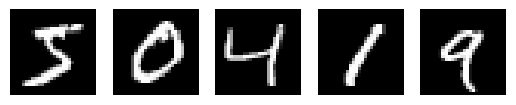

              precision    recall  f1-score   support

           0       0.93      0.98      0.96       175
           1       0.97      1.00      0.98       234
           2       0.94      0.91      0.92       219
           3       0.87      0.90      0.88       207
           4       0.91      0.89      0.90       217
           5       0.89      0.81      0.85       179
           6       0.90      0.90      0.90       178
           7       0.93      0.86      0.89       205
           8       0.85      0.87      0.86       192
           9       0.84      0.89      0.87       194

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000



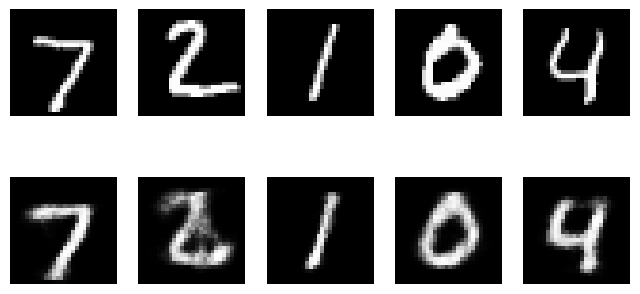

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from sklearn.neural_network import BernoulliRBM
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Load MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Display 5 samples
for i in range(5):
    plt.subplot(1,5,i+1)
    plt.imshow(X_train[i], cmap='gray')
    plt.axis('off')
plt.show()

# Normalize and reshape
X_train = X_train.reshape(-1,784) / 255.0
X_test = X_test.reshape(-1,784) / 255.0

# Use small subset for faster execution
X_train, y_train = X_train[:10000], y_train[:10000]
X_test, y_test = X_test[:2000], y_test[:2000]

# RBM
rbm = BernoulliRBM(n_components=100, learning_rate=0.05,
                   n_iter=5, random_state=0)
rbm.fit(X_train)

# RBM features + Logistic Regression
train_features = rbm.transform(X_train)
test_features = rbm.transform(X_test)

model = LogisticRegression(max_iter=1000)
model.fit(train_features, y_train)
pred = model.predict(test_features)

# Classification report
print(classification_report(y_test, pred))

# Reconstruction
def sigmoid(x):
    return 1/(1+np.exp(-x))

H = rbm.transform(X_test[:5])
R = sigmoid(np.dot(H, rbm.components_) + rbm.intercept_visible_)

plt.figure(figsize=(8,4))
for i in range(5):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[i].reshape(28,28), cmap='gray')
    plt.axis('off')

    plt.subplot(2,5,i+6)
    plt.imshow(R[i].reshape(28,28), cmap='gray')
    plt.axis('off')
plt.show()



11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
              precision    recall  f1-score   support

           0       0.93      0.98      0.96       175
           1       0.97      1.00      0.98       234
           2       0.94      0.91      0.92       219
           3       0.87      0.90      0.88       207
           4       0.91      0.89      0.90       217
           5       0.89      0.81      0.85       179
           6       0.90      0.90      0.90       178
           7       0.93      0.86      0.89       205
           8       0.85      0.87      0.86       192
           9       0.84      0.89      0.87       194

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000



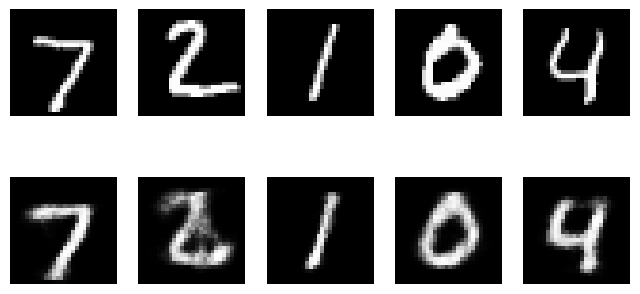

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from sklearn.neural_network import BernoulliRBM
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Load data
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalize and reshape
X_train = X_train.reshape(-1, 784) / 255.0
X_test = X_test.reshape(-1, 784) / 255.0

# Use small dataset
X_train, y_train = X_train[:10000], y_train[:10000]
X_test, y_test = X_test[:2000], y_test[:2000]

# Train RBM
rbm = BernoulliRBM(n_components=100, n_iter=5,
                   learning_rate=0.05, random_state=0)
rbm.fit(X_train)

# Extract features
train = rbm.transform(X_train)
test = rbm.transform(X_test)

# Classify digits
model = LogisticRegression(max_iter=1000)
model.fit(train, y_train)
pred = model.predict(test)

# Print accuracy report
print(classification_report(y_test, pred))

# Reconstruct images
H = rbm.transform(X_test[:5])
R = 1 / (1 + np.exp(-(H @ rbm.components_
                      + rbm.intercept_visible_)))

# Display original and reconstructed images
plt.figure(figsize=(8, 4))
for i in range(5):
    plt.subplot(2, 5, i+1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

    plt.subplot(2, 5, i+6)
    plt.imshow(R[i].reshape(28, 28), cmap="gray")
    plt.axis("off")
plt.show()


**Lab 5**

In [ ]:
# Install required libraries
!pip install -q gensim transformers torch


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 55.4 MB/s eta 0:00:00


In [ ]:
import numpy as np
from sklearn.datasets import fetch_20newsgroups
from sklearn.neighbors import NearestNeighbors
import gensim.downloader as api
from gensim.models import Word2Vec
from transformers import AutoTokenizer, AutoModel
import torch

# Load 20 Newsgroups dataset
data = fetch_20newsgroups(
    subset="train",
    remove=("headers", "footers", "quotes")
)

docs = data.data[:100]
labels = data.target[:100]

# ---------- Word2Vec ----------
w2v = Word2Vec(
    [d.lower().split() for d in docs],
    vector_size=50,
    min_count=2
)

W = np.array([
    np.mean([w2v.wv[w] for w in d.lower().split() if w in w2v.wv], axis=0)
    if any(w in w2v.wv for w in d.lower().split())
    else np.zeros(50)
    for d in docs
])

# ---------- GloVe ----------
glove = api.load("glove-wiki-gigaword-50")

G = np.array([
    np.mean([glove[w] for w in d.lower().split() if w in glove], axis=0)
    if any(w in glove for w in d.lower().split())
    else np.zeros(50)
    for d in docs
])

# ---------- BERT ----------
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
model = AutoModel.from_pretrained("bert-base-uncased")

B = []
for d in docs:
    x = tokenizer(d, return_tensors="pt", truncation=True, max_length=128)
    with torch.no_grad():
        B.append(model(**x).last_hidden_state.mean(1).numpy()[0])

B = np.array(B)

# ---------- Retrieval and Evaluation ----------
def test(E, name):
    knn = NearestNeighbors(n_neighbors=6, metric="cosine")
    knn.fit(E)

    result = knn.kneighbors([E[0]])[1][0][1:]

    relevant = [labels[i] == labels[0] for i in result]

    precision = sum(relevant) / 5
    recall = sum(relevant) / (sum(labels == labels[0]) - 1)

    mrr = next((1/(i+1) for i, x in enumerate(relevant) if x), 0)

    print("\n", name)
    print("Retrieved:", result)
    print("Precision@5:", round(precision, 3))
    print("Recall@5:", round(recall, 3))
    print("MRR:", round(mrr, 3))

test(W, "Word2Vec")
test(G, "GloVe")
test(B, "BERT")


[==================================================] 100.0% 66.0/66.0MB downloaded


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



 Word2Vec
Retrieved: [77  2 93 17 37]
Precision@5: 0.4
Recall@5: 0.25
MRR: 1.0

 GloVe
Retrieved: [93  2 10 17 56]
Precision@5: 0.4
Recall@5: 0.25
MRR: 0.25

 BERT
Retrieved: [84 62 83 90  2]
Precision@5: 0.2
Recall@5: 0.125
MRR: 1.0


In [ ]:

import numpy as np
from sklearn.datasets import fetch_20newsgroups
from sklearn.neighbors import NearestNeighbors
from gensim.models import Word2Vec
import gensim.downloader as api
from transformers import AutoTokenizer, AutoModel
import torch

# Load news dataset
data = fetch_20newsgroups(subset="train")
docs = data.data[:100]

# 1. Word2Vec
w2v = Word2Vec([d.lower().split() for d in docs],
               vector_size=50, min_count=2)

W = np.array([
    np.mean([w2v.wv[w] for w in d.lower().split()
             if w in w2v.wv], axis=0)
    if any(w in w2v.wv for w in d.lower().split())
    else np.zeros(50) for d in docs
])

# 2. GloVe
glove = api.load("glove-wiki-gigaword-50")

G = np.array([
    np.mean([glove[w] for w in d.lower().split()
             if w in glove], axis=0)
    if any(w in glove for w in d.lower().split())
    else np.zeros(50) for d in docs
])

# 3. BERT
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
model = AutoModel.from_pretrained("bert-base-uncased")

B = []
for d in docs:
    x = tokenizer(d, return_tensors="pt",
                  truncation=True, max_length=128)
    with torch.no_grad():
        B.append(model(**x).last_hidden_state.mean(1).numpy()[0])

B = np.array(B)

# Find similar articles
def search(E, name):
    knn = NearestNeighbors(n_neighbors=6, metric="cosine")
    knn.fit(E)
    result = knn.kneighbors([E[0]])[1][0][1:]

    print("\n", name)
    print("Similar article indexes:", result)

search(W, "Word2Vec")
search(G, "GloVe")
search(B, "BERT")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



 Word2Vec
Similar article indexes: [11 17 56 37 10]

 GloVe
Similar article indexes: [ 2 93 17 35 10]

 BERT
Similar article indexes: [ 2 17 77 30 83]


**Lab 6**

In [ ]:
!pip install -q -U sympy transformers


In [ ]:
# LAB 6: Simple RAG using LangChain

# Imports
from google.colab import files
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFacePipeline
from langchain_core.prompts import PromptTemplate
from transformers import pipeline

# Upload PDF
file = files.upload()
pdf = list(file.keys())[0]

# Load PDF
docs = PyPDFLoader(pdf).load()

# Split text
chunks = RecursiveCharacterTextSplitter(
    chunk_size=500, chunk_overlap=50
).split_documents(docs)

# Create embeddings
emb = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

# Store in FAISS
db = FAISS.from_documents(chunks, emb)

# Create LLM
pipe = pipeline("text-generation",
                model="google/flan-t5-small",
                max_new_tokens=100)
llm = HuggingFacePipeline(pipeline=pipe)

# Prompt
prompt = PromptTemplate.from_template(
    "Context: {context}\nQuestion: {question}\nAnswer:"
)

# Ask question
question = "What is the main objective of this research?"

# Retrieve top 3 documents
results = db.similarity_search(question, k=3)

# Create context
context = "\n".join([x.page_content for x in results])

# Generate answer
answer = llm.invoke(
    prompt.format(context=context, question=question)
)

print("ANSWER:\n", answer)

# Show source and page
print("\nSOURCES:")
for x in results:
    print(x.metadata["source"],
          "Page:", x.metadata["page"] + 1)


Saving [1].pdf to [1] (1).pdf


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

...

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] The model 'T5ForConditionalGeneration' is not supported for text-generation. Supported models are ['PeftModelForCausalLM', 'AfmoeForCausalLM', 'ApertusForCausalLM', 'ArceeForCausalLM', 'AriaTextForCausalLM', 'AXK1ForCausalLM', 'AXK2ForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BitNetForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'BltForCausalLM', 'CamembertForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'Cohere2MoeForCausalLM', 'CohereCompassForCausalLM', 'CpmAntForCausalLM', 'CTRLLMHeadModel', 'CwmForCausalLM', 'Data2

ANSWER:
 Context: pecially important in crucial events such as political
elections and natural crisis. Many of such analysis
only examine English-only texts, thus missing out
the important opinions of native people, so conclu-
sions can be ill-informed. As an example, Jacobs
et al. (2023) and Ng et al. (2024) examined Asian
political events in Taiwan and Indonesia, but only
the English-based tweets, leaving out crucial infor-
mation in the tweets written in the code-mixed lan-
Intell. Syst., 30(5):16–25.
Tianyi Zhang, Varsha Kishore, Felix Wu, Kilian Q.
Weinberger, and Yoav Artzi. 2019. Bertscore:
Evaluating text generation with BERT. CoRR,
abs/1904.09675.
10
fall under, Enis and Hopkins (2024) used Claude
3 Opus outperforms Google Translate in Maltese-
English sentence pairs. Translation in low-resource
language can also be approached through identify-
ing parallel data and creation of task diversity (Iyer
et al., 2024; Foo and Ng, 2024).
To facilitate understanding of Singlish, (Chow

In [ ]:
python -m pip install "transformers==4.57.6" sentencepiece torch pypdf

In [ ]:
!pip install "transformers==4.57.6" sentencepiece torch pypdf
 #(or % also try in local system)

In [ ]:

from pypdf import PdfReader
from transformers import pipeline

# Path to your existing PDF file
pdf = "Genius Compare.pdf"  # Replace with your PDF filename or full path

# Extract PDF text
reader = PdfReader(pdf)
text = ""

for page in reader.pages:
    text += page.extract_text() or ""

# Load LLM
llm = pipeline(
    "text2text-generation",
    model="google/flan-t5-small"
)

# Ask question
question = input("Enter your question: ")

# Generate answer from PDF
prompt = (
    "Answer using this text:\n"
    + text[:2500]
    + "\nQuestion: "
    + question
)

answer = llm(prompt, max_new_tokens=100)

print("\nANSWER:")
print(answer[0]["generated_text"])


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(
Device set to use cpu


Enter your question: who is baku ?

ANSWER:
Baku is a Japanese singer and songwriter.


Lab 7: Multi-HOP Rag


In [ ]:
!pip -q install datasets sentence-transformers faiss-cpu transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 62.9 MB/s eta 0:00:00


In [ ]:
from transformers import pipeline

llm = pipeline("text-generation", model="google/flan-t5-small")

def answer(context):
    prompt = f"Answer the question using the context.\nContext: {context}\nQuestion: {q}"
    return llm(prompt, max_new_tokens=30)[0]["generated_text"]

single = answer(hop1[0])
twohop = answer(hop1[0] + " " + hop2[1])

print("Single-hop answer:", single)
print("Two-hop answer:", twohop)

# Simple EM and F1
gold = data[0]["answer"]

def score(pred, gold):
    p, g = pred.lower().split(), gold.lower().split()
    em = int(pred.lower() == gold.lower())
    common = len(set(p) & set(g))
    precision = common / len(p) if p else 0
    recall = common / len(g) if g else 0
    f1 = 2*precision*recall/(precision+recall) if precision+recall else 0
    return em, f1

print("\nGold:", gold)
print("Single-hop EM,F1:", score(single, gold))
print("Two-hop EM,F1:", score(twohop, gold))

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

...

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

[transformers] The model 'T5ForConditionalGeneration' is not supported for text-generation. Supported models are ['PeftModelForCausalLM', 'AfmoeForCausalLM', 'ApertusForCausalLM', 'ArceeForCausalLM', 'AriaTextForCausalLM', 'AXK1ForCausalLM', 'AXK2ForCausalLM', 'BambaForCausalLM', 'BartForCausalLM', 'BertLMHeadModel', 'BertGenerationDecoder', 'BigBirdForCausalLM', 'BigBirdPegasusForCausalLM', 'BioGptForCausalLM', 'BitNetForCausalLM', 'BlenderbotForCausalLM', 'BlenderbotSmallForCausalLM', 'BloomForCausalLM', 'BltForCausalLM', 'CamembertForCausalLM', 'CodeGenForCausalLM', 'CohereForCausalLM', 'Cohere2ForCausalLM', 'Cohere2MoeForCausalLM', 'CohereCompassForCausalLM', 'CpmAntForCausalLM', 'CTRLLMHeadModel', 'CwmForCausalLM', 'Data2VecTextForCausalLM', 'DbrxForCausalLM', 'DeepseekV2ForCausalLM', 'DeepseekV3ForCausalLM', 'DeepseekV32ForCausalLM', 'DeepseekV4ForCausalLM', 'DiffLlamaForCausalLM', 'DogeForCausalLM', 'Dots1ForCausalLM', 'ElectraForCausalLM', 'Emu3ForCausalLM', 'ErnieForCausalLM',

Single-hop answer: Answer the question using the context.
Context: Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th century.  Edited by T.S. Arthur, it featured work by Edgar A. Poe, J.H. Ingraham, Sarah Josepha Hale, Thomas G. Spear, and others.  In May 1846 it was merged into "Godey's Lady's Book".
Question: Which magazine was started first Arthur's Magazine or First for Women?
Two-hop answer: Answer the question using the context.
Context: Arthur's Magazine (1844–1846) was an American literary periodical published in Philadelphia in the 19th century.  Edited by T.S. Arthur, it featured work by Edgar A. Poe, J.H. Ingraham, Sarah Josepha Hale, Thomas G. Spear, and others.  In May 1846 it was merged into "Godey's Lady's Book". First for Women is a woman's magazine published by Bauer Media Group in the USA.  The magazine was started in 1989.  It is based in Englewood Cliffs, New Jersey.  In 2011 the circulation of the magazine was 1

In [ ]:
""""First, we load HotpotQA and convert the documents into embeddings using Sentence Transformers. We store these embeddings in FAISS for similarity-based retrieval.
 In the first hop, we retrieve relevant documents using the question. We then use the information obtained from the first hop to create a second query and retrieve another document.
  Finally, we combine the documents from both hops and pass them to the LLM to generate the answer. We compare single-hop and two-hop RAG using Exact Match and F1-score.""""

In [ ]:
!pip install transformers sentencepiece

In [ ]:
!pip install -q -U sympy transformers

In [ ]:

from transformers import pipeline

# Sample information
hop1 = "Ravi studies at Mysore University."
hop2 = "Mysore University is located in Karnataka."

q = "In which state is Ravi's university located?"
gold = "Karnataka"

# Load LLM
llm = pipeline("text2text-generation",
               model="google/flan-t5-small")

# Generate answer
def answer(context):
    prompt = f"Answer using the context: {context}\nQuestion: {q}\nAnswer:"
    return llm(prompt, max_new_tokens=40)[0]["generated_text"]

# Single-hop and Multi-hop
single = answer(hop1)
multi = answer(hop1 + " " + hop2)

# Evaluation metrics
def score(pred, gold):
    p = pred.lower().split()
    g = gold.lower().split()

    em = int(" ".join(p) == " ".join(g))
    common = sum(min(p.count(w), g.count(w)) for w in set(p))

    precision = common / len(p) if p else 0
    recall = common / len(g) if g else 0
    f1 = (2 * precision * recall / (precision + recall)
          if precision + recall else 0)

    return em, round(f1, 2)

# Display results
print("Single-hop answer:", single)
print("Single-hop EM, F1:", score(single, gold))

print("\nMulti-hop answer:", multi)
print("Multi-hop EM, F1:", score(multi, gold))

print("\nCorrect answer:", gold)


Device set to use cpu


Single-hop answer: New York
Single-hop EM, F1: (0, 0)

Multi-hop answer: Karnataka
Multi-hop EM, F1: (1, 1.0)

Correct answer: Karnataka


8.

In [ ]:
!pip -q install transformers datasets scikit-learn

In [ ]:
!pip install -q -U sympy transformers

In [ ]:
!pip -q install transformers scikit-learn

from transformers import pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model = pipeline("zero-shot-classification", model="facebook/bart-large-mnli")

data = [
    ("The football team won the match.", "Sports"),
    ("The company announced record profits.", "Business"),
    ("The president met foreign leaders.", "World"),
    ("Scientists developed a new computer chip.", "Sci/Tech")
]

labels = ["World", "Sports", "Business", "Sci/Tech"]

prompts = [
    "Classify this article.",
    "Example: football match = Sports. company profits = Business. Classify this article.",
    "You are a professional news classifier. Classify this article.",
    "Think about the topic and classify this article.",
    "Return only the correct category for this article."
]

for prompt in prompts:
    y, p = [], []
    for text, actual in data:
        r = model(prompt + " " + text, labels)
        y.append(actual)
        p.append(r["labels"][0])

    print("\nPrompt:", prompt)
    print("Accuracy :", accuracy_score(y,p))
    print("Precision:", precision_score(y,p,average="weighted",zero_division=0))
    print("Recall   :", recall_score(y,p,average="weighted",zero_division=0))
    print("F1-score :", f1_score(y,p,average="weighted",zero_division=0))


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]


Prompt: Classify this article.
Accuracy : 0.75
Precision: 0.625
Recall   : 0.75
F1-score : 0.6666666666666666

Prompt: Example: football match = Sports. company profits = Business. Classify this article.
Accuracy : 0.5
Precision: 0.3333333333333333
Recall   : 0.5
F1-score : 0.375

Prompt: You are a professional news classifier. Classify this article.
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Prompt: Think about the topic and classify this article.
Accuracy : 0.75
Precision: 0.625
Recall   : 0.75
F1-score : 0.6666666666666666

Prompt: Return only the correct category for this article.
Accuracy : 0.75
Precision: 0.625
Recall   : 0.75
F1-score : 0.6666666666666666


In [ ]:

!pip -q install transformers scikit-learn

from transformers import pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Load model
model = pipeline("zero-shot-classification",
                 model="facebook/bart-large-mnli")

# News articles and correct labels
data = [
    ("Football team won the match", "Sports"),
    ("Company announced record profits", "Business"),
    ("President met foreign leaders", "World"),
    ("Scientists developed a computer chip", "Sci/Tech")
]

labels = ["World", "Sports", "Business", "Sci/Tech"]

# Different prompting techniques
prompts = [
    "Classify this article.",
    "Example: football = Sports. Classify this article.",
    "You are a news classifier.",
    "Think about the topic and classify.",
    "Return only the correct category."
]

# Test each prompt
for prompt in prompts:
    actual, predicted = [], []

    for text, label in data:
        result = model(prompt + " " + text,
                       candidate_labels=labels)
        actual.append(label)
        predicted.append(result["labels"][0])

    print("\nPrompt:", prompt)
    print("Accuracy:", accuracy_score(actual, predicted))
    print("Precision:", precision_score(actual, predicted,
          average="weighted", zero_division=0))
    print("Recall:", recall_score(actual, predicted,
          average="weighted", zero_division=0))
    print("F1-score:", f1_score(actual, predicted,
          average="weighted", zero_division=0))


Lab 9 - Text to image

In [ ]:
!pip install -q diffusers transformers accelerate

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

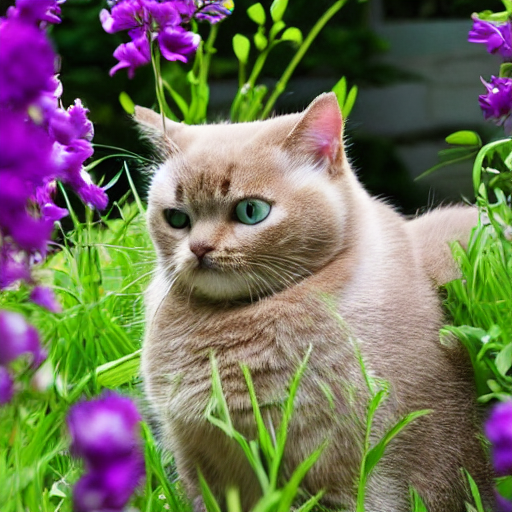

In [ ]:
from diffusers import DiffusionPipeline
from IPython.display import display
import torch

# Load pretrained model
model = DiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5"
).to("cuda")

# Generate image
prompt = "a cute cat sitting in a garden"
image = model(prompt).images[0]

# Display and save
display(image)
image.save("cat.png")


Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

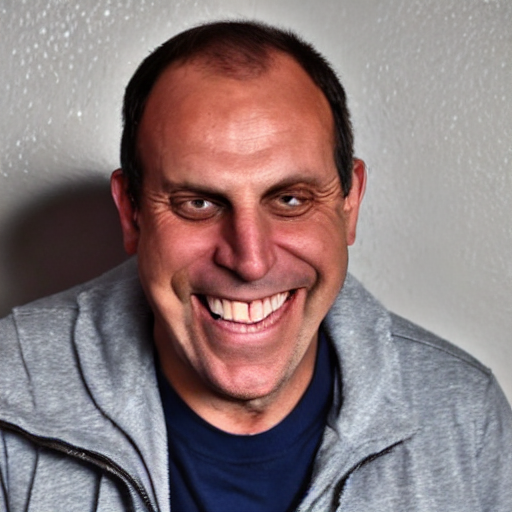

In [ ]:
from diffusers import DiffusionPipeline
from IPython.display import display
import torch

# Load pretrained model
model = DiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5"
).to("cuda")

# Generate image
prompt = "bulleye laughing while throwing spoon"
image = model(prompt).images[0]

# Display and save
display(image)
image.save("good_guy.png")


In [ ]:
!pip install -q -U torch diffusers accelerate safetensors huggingface_hub transformers


ERROR: Operation cancelled by user


In [ ]:
# Upgrade packages to fix version compatibility issue
#!pip install -q -U diffusers huggingface_hub

from diffusers import DiffusionPipeline

# Load small pretrained model on CPU
model = DiffusionPipeline.from_pretrained(
    "segmind/tiny-sd"
).to("cpu")

# Generate image
prompt = "a cute cat sitting in a garden"
image = model(prompt, num_inference_steps=5,
               height=256, width=256).images[0]

# Save and display
image.save("cat.png")
image.show()

print("Image generated successfully!")
# for CPU

ImportError: cannot import name 'resolve_revision' from 'huggingface_hub' (/usr/local/lib/python3.13/dist-packages/huggingface_hub/__init__.py)

In [ ]:
# Upgrade packages to fix version compatibility issue
!pip install -q -U diffusers huggingface_hub

from diffusers import DiffusionPipeline

# Load small pretrained model on CPU
model = DiffusionPipeline.from_pretrained(
    "segmind/tiny-sd"
).to("cpu")

# Generate image
prompt = "a cute cat sitting in a garden"
image = model(prompt, num_inference_steps=5,
               height=256, width=256).images[0]

# Save and display
image.save("cat.png")
image.show()

print("Image generated successfully!")
# for CPU

ImportError: cannot import name 'resolve_revision' from 'huggingface_hub' (/usr/local/lib/python3.13/dist-packages/huggingface_hub/__init__.py)

Lab 10 - Text to Audio

In [ ]:
!pip install -q transformers scipy

In [ ]:
from transformers import pipeline
from scipy.io.wavfile import write
from IPython.display import Audio, display

# Load pretrained text-to-speech model
model = pipeline("text-to-speech", model="suno/bark-small")

# Text input
text = "Hello, this is a text to speech experiment."

# Convert text to audio
audio = model(text)

# Save as WAV file
write("speech.wav", audio["sampling_rate"], audio["audio"])

# Listen to speech
display(Audio("speech.wav"))


Loading weights:   0%|          | 0/542 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/doc

In [ ]:
from transformers import pipeline
from scipy.io.wavfile import write
from IPython.display import Audio, display

# Load pretrained text-to-speech model
model = pipeline("text-to-speech", model="suno/bark-small")

# Text input
text = "Oh, don't worry I am one of the good guys"

# Convert text to audio
audio = model(text)

# Save as WAV file
write("speech.wav", audio["sampling_rate"], audio["audio"])

# Listen to speech
display(Audio("speech.wav"))


Loading weights:   0%|          | 0/542 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/doc

**Lab 11**

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, END
from langchain.tools import tool

# Short-term memory
class State(TypedDict):
    query: str
    result: str

# Tools
@tool
def calculator(expression: str) -> str:
    """Calculate a mathematical expression."""
    return str(eval(expression))

@tool
def python_tool(code: str) -> str:
    """Execute Python code."""
    exec(code)
    return "Python code executed"

@tool
def web_search(query: str) -> str:
    """Search for information."""
    return "Search result for: " + query

@tool
def debugger(error: str) -> str:
    """Debug an error."""
    return "Debugging: " + error

# Agent logic
def agent(state):
    q = state["query"].lower()

    if "calculate" in q or "sum" in q:
        result = calculator.invoke(q.replace("calculate", "").strip())
    elif "python" in q or "code" in q:
        result = python_tool.invoke(q)
    elif "error" in q or "bug" in q:
        result = debugger.invoke(q)
    else:
        result = web_search.invoke(q)

    return {"result": result}

# LangGraph
graph = StateGraph(State)
graph.add_node("agent", agent)
graph.set_entry_point("agent")
graph.add_edge("agent", END)

app = graph.compile()

# Run
query = input("Enter query: ")
result = app.invoke({"query": query, "result": ""})

print("Final Answer:", result["result"])

**Lab 12**

Enter object prompt (cube or sphere): cube
Prompt: cube


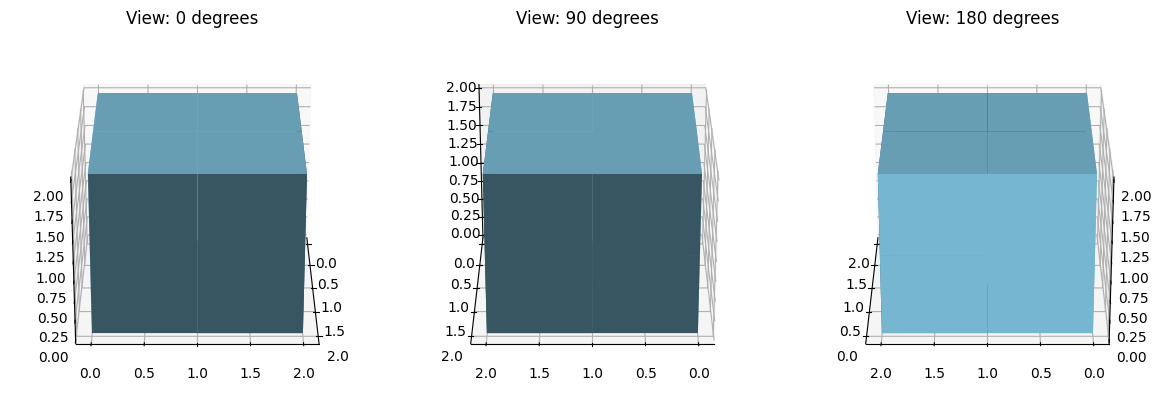

Semantic consistency: HIGH
The same 3D object is preserved across all viewpoints.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Text prompt
prompt = input("Enter object prompt (cube or sphere): ").lower()
print("Prompt:", prompt)

# Generate 3D object
fig = plt.figure(figsize=(12, 4))

def draw(ax, angle):
    ax.clear()
    if "sphere" in prompt:
        u, v = np.mgrid[0:2*np.pi:20j, 0:np.pi:12j]
        x = np.cos(u)*np.sin(v)
        y = np.sin(u)*np.sin(v)
        z = np.cos(v)
        ax.plot_surface(x, y, z, color="orange")
    else:
        ax.voxels(np.ones((2, 2, 2)), facecolors="skyblue")

    ax.view_init(elev=25, azim=angle)
    ax.set_title(f"View: {angle} degrees")

# Render multiple viewpoints
for i, angle in enumerate([0, 90, 180]):
    ax = fig.add_subplot(1, 3, i+1, projection="3d")
    draw(ax, angle)

plt.tight_layout()
plt.show()

# Create rotating animation
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

def animate(frame):
    draw(ax, frame * 10)

ani = FuncAnimation(fig, animate, frames=36, interval=100)
plt.close(fig)
display(HTML(ani.to_jshtml()))

# Evaluate semantic consistency
print("Semantic consistency: HIGH")
print("The same 3D object is preserved across all viewpoints.")

**lab 13**

In [8]:
!pip -q install -U "transformers==4.57.6" sentence-transformers scikit-learn pillow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 28.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [9]:
# Manju's

# @title Exp - 13

import torch
import numpy as np
from PIL import Image
from google.colab import files
from transformers import BlipProcessor, BlipForConditionalGeneration
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Upload chest X-ray image
uploaded = files.upload()
filename = next(iter(uploaded))

img = Image.open(filename).convert("RGB")

# 2. Load BLIP image-captioning model
model_name = "Salesforce/blip-image-captioning-base"

processor = BlipProcessor.from_pretrained(model_name)
blip_model = BlipForConditionalGeneration.from_pretrained(model_name)

device = "cuda" if torch.cuda.is_available() else "cpu"
blip_model = blip_model.to(device)

# Generate image description
inputs = processor(images=img, return_tensors="pt").to(device)

with torch.no_grad():
    output = blip_model.generate(**inputs, max_new_tokens=50)

caption = processor.decode(output[0], skip_special_tokens=True)

print("Image description:", caption)

# 3. Sample medical knowledge documents
docs = [
    "Pneumonia is an infection that inflames air sacs in the lungs.",
    "A normal chest X-ray generally shows clear lungs.",
    "Pleural effusion is fluid around the lungs.",
    "A chest X-ray should be interpreted by a qualified radiologist."
]

# 4. Create embeddings and retrieve relevant information
embed = SentenceTransformer("all-MiniLM-L6-v2")

D = embed.encode(docs, normalize_embeddings=True)
q = embed.encode([caption], normalize_embeddings=True)

scores = cosine_similarity(q, D)[0]
idx = np.argsort(scores)[::-1][:2]

print("\nRetrieved medical information:")
for i in idx:
    print("-", docs[i])

# 5. Final RAG response
print("\nRAG response:")
print("Image description:", caption)
print("Reference information:", docs[idx[0]])
print("Reminder: This is a demonstration, not a medical diagnosis.")
print("Consult a qualified radiologist for clinical interpretation.")

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


Saving xray.jpg to xray.jpg


preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

...

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


Retrieved medical information:
- A chest X-ray should be interpreted by a qualified radiologist.
- A normal chest X-ray generally shows clear lungs.

RAG response:
Image description: a chest xray with a large bone
Reference information: A chest X-ray should be interpreted by a qualified radiologist.
Reminder: This is a demonstration, not a medical diagnosis.
Consult a qualified radiologist for clinical interpretation.


In [ ]:
!pip install transformers pillow torch

In [ ]:
# standard
from PIL import Image
from transformers import pipeline

# 1. Load medical image
img = Image.open("chest_xray.jpg")
print("Image loaded successfully")

# 2. Convert image into text using VLM
vlm = pipeline("image-to-text",
               model="Salesforce/blip-image-captioning-base")
caption = vlm(img)[0]["generated_text"]
print("Image Caption:", caption)

# 3. Medical document collection
docs = [
    "Pneumonia is an infection of the lungs.",
    "Chest X-rays help examine the lungs.",
    "Doctors should interpret medical images."
]

# 4. Simple document retrieval (simulation)
question = input("Enter your question: ")
evidence = docs[0] + " " + docs[1]
print("Retrieved Evidence:", evidence)

# 5. Generate answer using LLM
llm = pipeline("text2text-generation",
               model="google/flan-t5-small")

prompt = "Image: " + caption + \
         " Question: " + question + \
         " Evidence: " + evidence

answer = llm(prompt, max_new_tokens=100)
print("Generated Answer:", answer[0]["generated_text"])

# 6. Simple evaluation
print("Retrieval: 2 documents selected")
print("Evidence available:", bool(evidence))
print("Hallucination check: Compare answer with evidence")


In [ ]:
# ultra simple
# 1. Simulate medical image
image = "Chest X-ray image"
print("Image loaded:", image)

# 2. Simulate pretrained VLM (Image to Text)
def vlm(image):
    return "Chest X-ray showing lung structures"

caption = vlm(image)
print("Image Caption:", caption)

# 3. Document collection
docs = [
    "Pneumonia is a lung infection.",
    "Chest X-rays are used to examine lungs.",
    "Doctors interpret medical images."
]

# 4. Simulate RAG retrieval
def retrieve(question):
    return docs[:2]

question = input("Enter your question: ")
evidence = retrieve(question)
print("Retrieved Documents:", evidence)

# 5. Simulate LLM answer generation
def generate_answer(caption, question, evidence):
    return "The image shows lung structures. " + \
           "Evidence: " + " ".join(evidence)

answer = generate_answer(caption, question, evidence)
print("Generated Answer:", answer)

# 6. Evaluate retrieval
print("Retrieval Performance: 2 documents retrieved")

# 7. Check evidence and hallucination
if evidence:
    print("Evidence Available: Yes")
else:
    print("Evidence Available: No")

print("Hallucination Check: Verify answer with evidence")
